## Run the gravity calculation using the following equation:

#### Gravity_mat=(Campsites_mat*Population_mat)/Distance_mat

In [2]:
import pandas as pd
import numpy as np
import os

os.chdir('/..')
os.chdir('Users/alexp/OneDrive - University of New Brunswick/Grad Studies/Modelling_transport_pathways/Clean_data_sets')

In [3]:
#import CSV into a dataframe of distance from campground population of urban centre and number of campsites
Camp_Dist_Pop_Sites=pd.read_csv('Campground_Dist_Pop_Sites_matrix.csv',index_col=0)
Camp_Dist_Pop_Sites.head(3)

,Distance_Km,Distance_Km.1,Distance_Km.2,Distance_Km.3,Distance_Km.4,Sites,Sites.1,Sites.2,Sites.3,Sites.4,Population,Population.1,Population.2,Population.3,Population.4
Origin,Bedford,Edmunston,Fredericton,Moncton,Oromocto,Bedford,Edmunston,Fredericton,Moncton,Oromocto,Bedford,Edmunston,Fredericton,Moncton,Oromocto
Campground,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ADDA Fundy Tides CG- City,224.4405136,521.3435569000001,315.645877,146.7486065,300.99828239999994,35.0,35.0,35.0,35.0,35.0,403131,12086,58220,71889,9223


In [4]:
#Split the dataframe into 3 separate dataframes: 1. distance for origin to campground, 2. Number of campsites, 3. population of origin
Distance_df=Camp_Dist_Pop_Sites[['Distance_Km','Distance_Km.1','Distance_Km.2','Distance_Km.3','Distance_Km.4']]
Campsites_df=Camp_Dist_Pop_Sites[['Sites','Sites.1','Sites.2','Sites.3','Sites.4']]
Population_df=Camp_Dist_Pop_Sites[['Population','Population.1','Population.2','Population.3','Population.4']]

In [5]:
#Rename columns to include origin location and remove the columns that aren't needed anymore
Distance_df=Distance_df.rename(columns={'Distance_Km':'Bedford','Distance_Km.1':'Edmunston','Distance_Km.2':'Fredericton','Distance_Km.3':'Moncton','Distance_Km.4':'Oromocto'}).drop(index=['Origin', 'Campground'])
Campsites_df=Campsites_df.rename(columns={'Sites':'Bedford','Sites.1':'Edmunston','Sites.2':'Fredericton','Sites.3':'Moncton','Sites.4':'Oromocto'}).drop(index=['Origin', 'Campground'])
Population_df=Population_df.rename(columns={'Population':'Bedford','Population.1':'Edmunston','Population.2':'Fredericton','Population.3':'Moncton','Population.4':'Oromocto'}).drop(index=['Origin', 'Campground'])

In [6]:
# convert dataframe to a numpy matrix and convert values to float
Distance_mat=Distance_df.to_numpy().astype(float)
Campsites_mat=Campsites_df.to_numpy().astype(float)
Population_mat=Population_df.to_numpy().astype(float)

In [7]:
#Calculating gravity matrix 
Gravity_mat=(Campsites_mat*Population_mat)/Distance_mat
#Gravity_mat

In [8]:
#Convert numpy matrix back to a dataframe and return to a pandas dataframe
def conv_to_df(matrix,row_name):
    import numpy as mp
    import pandas as pd
    Gravity_df = pd.DataFrame(matrix,index=row_name.index, columns = ['Bedford','Edmunston','Fredericton','Moncton','Oromocto'])
    return Gravity_df
Gravity_df = conv_to_df(Gravity_mat,Campsites_df)
Gravity_df = Gravity_df[Gravity_df != 0]
Gravity_df = Gravity_df.dropna()

In [9]:
#Write to csv
Gravity_df.to_csv('Gravity_calc.csv')

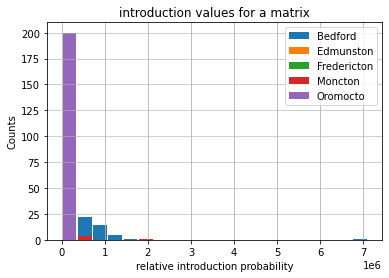

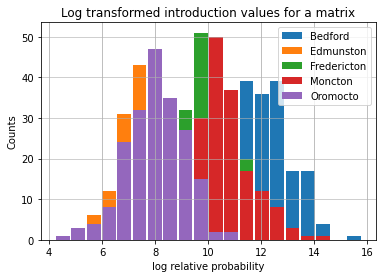

In [10]:
#plot histogram of the distribution by origin location. 
import matplotlib.pyplot as plt

Gravity_df.plot.hist(grid=True, bins=20, rwidth=0.9)
plt.title('introduction values for a matrix')
plt.xlabel('relative introduction probability')
plt.ylabel('Counts')
plt.grid(axis='y', alpha=0.75)

np.log(Gravity_df).plot.hist(grid=True, bins=20, rwidth=0.9)
plt.title('Log transformed introduction values for a matrix')
plt.xlabel('log relative probability')
plt.ylabel('Counts')
plt.grid(axis='y', alpha=0.75)

In [11]:
#Rejoin dataframes and export as
df= pd.concat([Distance_df, Campsites_df, Population_df], axis=1)

In [19]:
df.stack().reset_index()

TypeError: stack() got an unexpected keyword argument 'columns'

In [17]:
df

,Bedford,Edmunston,Fredericton,Moncton,Oromocto,Bedford,Edmunston,Fredericton,Moncton,Oromocto,Bedford,Edmunston,Fredericton,Moncton,Oromocto
ADDA Fundy Tides CG- City,224.4405136,521.3435569000001,315.645877,146.7486065,300.99828239999994,35.0,35.0,35.0,35.0,35.0,403131,12086,58220,71889,9223
Adventures East Campground & Cottages,332.7059895,761.1695037000001,555.4718238,386.57455319999997,540.8242292,85.0,85.0,85.0,85.0,85.0,403131,12086,58220,71889,9223
All Done Camping,313.6656619,352.8948139,121.22389790000001,62.89080768,106.53769199999999,46.0,46.0,46.0,46.0,46.0,403131,12086,58220,71889,9223
All Points East Campground,392.95751129999996,611.1951802,415.2832887,247.20889069999996,400.6356941,40.0,40.0,40.0,40.0,40.0,403131,12086,58220,71889,9223
Amherst Shore Provincial Park,191.455803,459.08289400000007,257.0057688,88.1084983,242.3581742,42.0,42.0,42.0,42.0,42.0,403131,12086,58220,71889,9223
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Whycocomagh Provincial Park,305.8217089,734.2852231,528.5875432,359.6902727,513.9399486000001,33.0,33.0,33.0,33.0,33.0,403131,12086,58220,71889,9223
Williams Brook- Mount Carleton Provincial Park,539.1038212000001,148.96122219999998,237.76717620000002,288.4515685,256.82368399999996,8.0,8.0,8.0,8.0,8.0,403131,12086,58220,71889,9223
Winter Bay Tent & Trailer Park,314.47987789999996,532.7175467000001,336.8056552,168.7312572,322.1580606,0.0,0.0,0.0,0.0,0.0,403131,12086,58220,71889,9223
Woolastook Park Campground,415.7827416,238.80378030000003,24.67681287,190.21445930000002,37.08335544,0.0,0.0,0.0,0.0,0.0,403131,12086,58220,71889,9223
